# Heart Disease Prediction System

**Live Deployment Link:** `PASTE YOUR LIVE DEPLOYMENT LINK HERE`

| | |
|---|---|
| **Student Name** | `YOUR NAME` |
| **Registration No.** | `YOUR REGISTRATION NUMBER` |
| **Course** | Machine Learning Fundamentals (AIC354), BS (CS), Fall 2026 |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Assignment** | Assignment 2: Developing an End-to-End Machine Learning System (Task 2) |
| **Dataset** | Heart Disease Data Set (Cleveland database), UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/45/heart+disease |
| **Model** | Support Vector Classifier (with feature scaling) |

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (1) or does not have heart disease (0) from four medical measurements.
##### **Application** Screening support and learning: it shows how the four phases of the Machine Learning cycle (Training, Testing, Application, Feedback) are applied to structured medical data.

> **Disclaimer:** this is an educational model trained on 303 patients. It is **not** a medical diagnosis tool.

## Input and Output

### Inputs (Features / Attributes): 4 attributes

| **Input Attribute** | **Meaning** | **Range of Values** |
| :--- | :--- | :--- |
| **age** | Age of the patient in years | 29 to 77 |
| **thalach** | Maximum heart rate achieved during the exercise test (beats per minute) | 71 to 202 |
| **exang** | Exercise-induced angina (chest pain during exercise) | 0 = No, 1 = Yes |
| **oldpeak** | ST depression induced by exercise relative to rest (a value read from the ECG) | 0.0 to 6.2 |

### Output (Prediction): 1 attribute

| **Output Attribute** | **Possible Values** |
| :--- | :--- |
| **HeartDisease** | 0 = No heart disease, 1 = Heart disease present |

The original UCI target column `num` has values 0 to 4 (0 = no disease, 1 to 4 = increasing severity). As is standard for this dataset, it is converted to a binary output in Step 3.2.

**No label encoding is needed in this project**, because all four inputs and the output are already numeric (see Step 5).

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data (including Exploratory Data Analysis)
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction (selecting the 4 input attributes)
- Step 5: Label Encoding (not required)
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs / Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
  - Step 7.6: Why These 4 Attributes? (Cross-Validation on Training Data Only)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector (not required)
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- Conclusion

**Files this notebook needs in the same folder:** `processed_cleveland.csv`
**Files this notebook creates:** `heart-disease-sample-data.csv`, `training-data.csv`, `testing-data.csv`, `heart_disease_model.pkl`, `model-predictions.csv`

## Code: Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
Imports the libraries needed to load data, split it, scale the inputs,
train a Support Vector Classifier, evaluate it, and show results.
"""
import sys
import itertools

# Numerical computing (arrays, math)
import numpy as np

# Data manipulation (DataFrames, reading / writing CSV files)
import pandas as pd

# Saving and loading the trained model
import pickle

# Splitting the data and cross-validation
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RepeatedStratifiedKFold

# Scaling (puts all inputs on a similar numeric range) and a pipeline to chain scaler + model
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Support Vector Machine classifier
from sklearn import svm

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Pretty console tables
from prettytable import PrettyTable

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python       :", sys.version.split()[0])
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)

Python       : 3.12.3
NumPy        : 2.2.6
pandas       : 2.3.3
scikit-learn : 1.7.2


### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
Loads the Cleveland Heart Disease data from a CSV file into a pandas DataFrame.
'processed_cleveland.csv' is the UCI file 'processed.cleveland.data' with one
header row (the 14 attribute names) added. No values were changed.
The UCI file marks missing values with '?', so we tell pandas to read '?' as missing.
"""
sample_data = pd.read_csv("processed_cleveland.csv", na_values="?")

print("\n\nSample Data (first 10 rows):")
print("============================\n")
print(sample_data.head(10))
print("\nShape (rows, columns):", sample_data.shape)



Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

The file has 14 attributes. Only the four inputs highlighted below and the output are used in this project (see Step 4).

| Attribute | Meaning | Used? |
|---|---|---|
| age | Age in years | **Input** |
| sex | 1 = male, 0 = female | no |
| cp | Chest pain type (1 to 4) | no |
| trestbps | Resting blood pressure (mm Hg) | no |
| chol | Serum cholesterol (mg/dl) | no |
| fbs | Fasting blood sugar > 120 mg/dl (1 = yes) | no |
| restecg | Resting ECG result (0 to 2) | no |
| thalach | Maximum heart rate achieved | **Input** |
| exang | Exercise-induced angina (1 = yes) | **Input** |
| oldpeak | ST depression induced by exercise | **Input** |
| slope | Slope of the peak exercise ST segment | no |
| ca | Number of major vessels coloured by fluoroscopy | no |
| thal | Thalassemia test result | no |
| num | Diagnosis of heart disease (0 to 4) | **Output** (after conversion) |

In [3]:
"""
Purpose of this section:
-------------------------
Understand the dataset: attribute names, number of instances, data types,
missing values, and basic statistics.
"""
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(list(sample_data.columns))

print("\n\nNumber of Instances in Sample Data:", sample_data.shape[0])
print("====================================\n")

print("Data types:")
print("===========\n")
print(sample_data.dtypes)

print("\n\nMissing values per attribute (only attributes with at least one):")
print("=================================================================\n")
missing = sample_data.isna().sum()
print(missing[missing > 0])

print("\n\nOriginal output attribute 'num' (0 = no disease, 1-4 = disease of increasing severity):")
print("=======================================================================================\n")
print(sample_data["num"].value_counts().sort_index())



Attributes in Sample Data:

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


Number of Instances in Sample Data: 303

Data types:

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object


Missing values per attribute (only attributes with at least one):

ca      4
thal    2
dtype: int64


Original output attribute 'num' (0 = no disease, 1-4 = disease of increasing severity):

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


**Exploratory Data Analysis (EDA)** of the four input attributes and the output. The output is first converted to 0 / 1 here only for plotting; the official conversion is Step 3.2.


Summary statistics of the four input attributes:

          age  thalach   exang  oldpeak
count  303.00   303.00  303.00   303.00
mean    54.44   149.61    0.33     1.04
std      9.04    22.88    0.47     1.16
min     29.00    71.00    0.00     0.00
25%     48.00   133.50    0.00     0.00
50%     56.00   153.00    0.00     0.80
75%     61.00   166.00    1.00     1.60
max     77.00   202.00    1.00     6.20


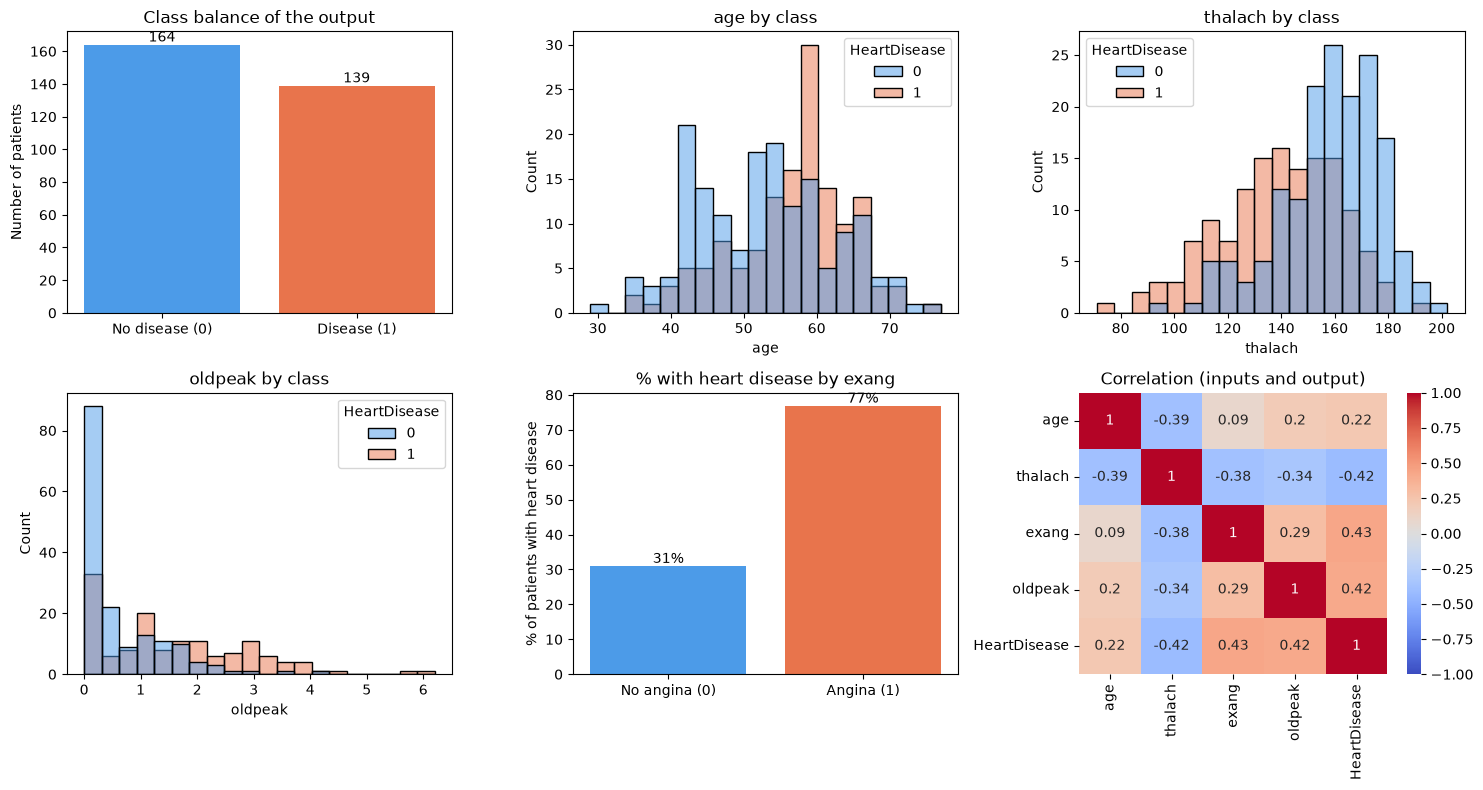

In [4]:
"""
Purpose of this section:
-------------------------
Exploratory Data Analysis (EDA): summary statistics, class balance,
distribution of every input attribute per class, and correlations.
"""
eda = sample_data[["age", "thalach", "exang", "oldpeak"]].copy()
eda["HeartDisease"] = (sample_data["num"] > 0).astype(int)

print("\nSummary statistics of the four input attributes:")
print("================================================\n")
print(eda[["age", "thalach", "exang", "oldpeak"]].describe().round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# 1. Class balance
counts = eda["HeartDisease"].value_counts().sort_index()
axes[0, 0].bar(["No disease (0)", "Disease (1)"], counts.values, color=["#4c9be8", "#e8744c"])
axes[0, 0].set_title("Class balance of the output")
axes[0, 0].set_ylabel("Number of patients")
for i, v in enumerate(counts.values):
    axes[0, 0].text(i, v + 2, str(v), ha="center")

# 2-4. Histograms of the continuous inputs, split by class
for ax, col in zip([axes[0, 1], axes[0, 2], axes[1, 0]], ["age", "thalach", "oldpeak"]):
    sns.histplot(data=eda, x=col, hue="HeartDisease", bins=20, kde=False,
                 palette=["#4c9be8", "#e8744c"], ax=ax)
    ax.set_title(f"{col} by class")

# 5. exang vs disease
exang_rate = eda.groupby("exang")["HeartDisease"].mean() * 100
axes[1, 1].bar(["No angina (0)", "Angina (1)"], exang_rate.values, color=["#4c9be8", "#e8744c"])
axes[1, 1].set_title("% with heart disease by exang")
axes[1, 1].set_ylabel("% of patients with heart disease")
for i, v in enumerate(exang_rate.values):
    axes[1, 1].text(i, v + 1, f"{v:.0f}%", ha="center")

# 6. Correlation heat-map
sns.heatmap(eda.corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1, 2])
axes[1, 2].set_title("Correlation (inputs and output)")

plt.tight_layout()
plt.show()

#### Step 3.2: Pre-process Sample Data

In [5]:
"""
Purpose of this section:
-------------------------
Pre-processing steps applied to the data:
1. Convert the original output 'num' (0-4) into a binary output 'HeartDisease':
      0        -> 0  (no heart disease)
      1,2,3,4  -> 1  (heart disease present)
2. Check the attributes we will use for missing values.
3. Check for duplicate rows.
"""
sample_data["HeartDisease"] = (sample_data["num"] > 0).astype(int)

print("Output after conversion (HeartDisease):")
print("=======================================\n")
print(sample_data["HeartDisease"].value_counts().sort_index().rename({0: "0 (no disease)", 1: "1 (disease)"}))

used_columns = ["age", "thalach", "exang", "oldpeak", "HeartDisease"]
print("\nMissing values in the attributes we use:", int(sample_data[used_columns].isna().sum().sum()))
print("Duplicate rows in the whole data      :", int(sample_data.duplicated().sum()))
print("\nNote: 'ca' (4 values) and 'thal' (2 values) have missing entries, but they are not")
print("used by this model, so no rows need to be removed or filled in.")

Output after conversion (HeartDisease):

HeartDisease
0 (no disease)    164
1 (disease)       139
Name: count, dtype: int64

Missing values in the attributes we use: 0
Duplicate rows in the whole data      : 0

Note: 'ca' (4 values) and 'thal' (2 values) have missing entries, but they are not
used by this model, so no rows need to be removed or filled in.


### Step 4: Feature Extraction
Out of the 13 available input attributes, **exactly 4 are selected** (as required by the assignment): `age`, `thalach`, `exang` and `oldpeak`.

How they were chosen: every possible group of 4 attributes (from the 11 attributes that have no missing values) was scored with 5-fold cross-validation on the **training data only**; this group scored highest. The test data was not used for the selection. The full comparison is shown in Step 7.6.

In [6]:
"""
Purpose of this section:
-------------------------
Keeps only the 4 selected input attributes and the output, records the valid
range of every input (used later to check user input), and saves the
reduced dataset to a CSV file.
"""
input_attributes = ["age", "thalach", "exang", "oldpeak"]

sample_data_reduced = sample_data[input_attributes + ["HeartDisease"]].copy()
sample_data_reduced.to_csv("heart-disease-sample-data.csv", index=False, header=True)

print("Sample data with the 4 selected inputs and the output (first 10 rows):")
print("======================================================================\n")
print(sample_data_reduced.head(10))
print("\nSaved: heart-disease-sample-data.csv  ->", sample_data_reduced.shape[0], "rows,", sample_data_reduced.shape[1], "columns")

# Range of values of each input attribute (minimum and maximum seen in the data)
input_ranges = {c: (float(sample_data_reduced[c].min()), float(sample_data_reduced[c].max())) for c in input_attributes}

print("\n\nRange of values of each input attribute:")
print("========================================\n")
range_table = PrettyTable(["Input attribute", "Minimum", "Maximum"])
for c, (lo, hi) in input_ranges.items():
    range_table.add_row([c, lo, hi])
print(range_table)

Sample data with the 4 selected inputs and the output (first 10 rows):

    age  thalach  exang  oldpeak  HeartDisease
0  63.0    150.0    0.0      2.3             0
1  67.0    108.0    1.0      1.5             1
2  67.0    129.0    1.0      2.6             1
3  37.0    187.0    0.0      3.5             0
4  41.0    172.0    0.0      1.4             0
5  56.0    178.0    0.0      0.8             0
6  62.0    160.0    0.0      3.6             1
7  57.0    163.0    1.0      0.6             0
8  63.0    147.0    0.0      1.4             1
9  53.0    155.0    1.0      3.1             1

Saved: heart-disease-sample-data.csv  -> 303 rows, 5 columns


Range of values of each input attribute:

+-----------------+---------+---------+
| Input attribute | Minimum | Maximum |
+-----------------+---------+---------+
|       age       |   29.0  |   77.0  |
|     thalach     |   71.0  |  202.0  |
|      exang      |   0.0   |   1.0   |
|     oldpeak     |   0.0   |   6.2   |
+-----------------+------

### Step 5: Label Encoding (not required)
- All four input attributes (`age`, `thalach`, `exang`, `oldpeak`) are **already numeric**.
- The output (`HeartDisease`) is **already 0 / 1**.
- Therefore **no Label Encoding code is needed**, and none is used in this notebook.

The one numeric adjustment this data does need is **feature scaling**. The inputs live on very different scales (for example `thalach` is around 150 while `exang` is only 0 or 1), and a Support Vector Classifier is sensitive to that. Scaling is therefore done inside the model itself in Step 6.3 (a `StandardScaler` followed by the classifier). It learns its scaling values from the **training data only**, and it is saved together with the model in the same `.pkl` file, so the saved model accepts raw values like `age = 58`.

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [7]:
"""
Purpose of this section:
-------------------------
Splits the dataset into Training Data (80%) and Testing Data (20%).
- Training Data teaches the model.
- Testing Data checks how well it works on patients it has never seen.
random_state=0 makes the split the same every time.
stratify keeps the share of disease / no-disease patients the same in both parts.
"""
training_data, testing_data = train_test_split(
    sample_data_reduced,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_reduced["HeartDisease"]
)

training_data.to_csv("training-data.csv", index=False, header=True)
testing_data.to_csv("testing-data.csv", index=False, header=True)

print("Training Data shape:", training_data.shape)
print("Testing Data shape :", testing_data.shape)
print("\nShare of patients with heart disease -> training: {:.1%}, testing: {:.1%}".format(
    training_data["HeartDisease"].mean(), testing_data["HeartDisease"].mean()))
print("\nSaved: training-data.csv, testing-data.csv")

Training Data shape: (242, 5)
Testing Data shape : (61, 5)

Share of patients with heart disease -> training: 45.9%, testing: 45.9%

Saved: training-data.csv, testing-data.csv


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
"""
Purpose of this section:
-------------------------
Separates the input vectors (4 attributes) from the output labels (HeartDisease)
of the training data.
"""
input_vector_train = training_data.iloc[:, :-1]
output_label_train = training_data.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.3: Train the Support Vector Classifier

In [9]:
"""
Purpose of this section:
-------------------------
Trains a Support Vector Classifier (SVC): a model that finds the best boundary
separating patients with and without heart disease.

The model is a two-step pipeline:
   1. StandardScaler : rescales every input to a similar range (learned from training data only)
   2. SVC            : the classifier itself (same settings as the Titanic notebook)
"""
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = make_pipeline(StandardScaler(), svm.SVC(gamma="auto", random_state=0))

svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(gamma='auto', random_state=0))])


#### Step 6.4: Save the Trained Model

In [10]:
"""
Purpose of this section:
-------------------------
Saves the trained model (scaler + SVC) to a file so it can be reused later
without training again.
"""
pickle.dump(svc_model, open("heart_disease_model.pkl", "wb"))
print("Saved: heart_disease_model.pkl")

Saved: heart_disease_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs / Labels of Testing Data

In [11]:
"""
Purpose of this section:
-------------------------
Separates the input vectors and the output labels of the testing data.
"""
input_vector_test = testing_data.iloc[:, :-1]
output_label_test = testing_data.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [12]:
"""
Purpose of this section:
-------------------------
Loads the previously saved model from disk (no retraining happens here).
"""
model = pickle.load(open("heart_disease_model.pkl", "rb"))
print("Model loaded from heart_disease_model.pkl")

Model loaded from heart_disease_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [13]:
"""
Purpose of this section:
-------------------------
Uses the loaded model to predict the output for every patient in the testing data
and saves the predictions next to the true labels.
"""
model_predictions = model.predict(input_vector_test)

model_predictions_df = testing_data.copy()
model_predictions_df["Predictions"] = model_predictions
model_predictions_df.to_csv("model-predictions.csv", index=False, header=True)

print("\n\nPredictions Returned by the Trained Model (testing data):")
print("=========================================================\n")
print(model_predictions_df)
print("\nSaved: model-predictions.csv")



Predictions Returned by the Trained Model (testing data):

      age  thalach  exang  oldpeak  HeartDisease  Predictions
125  45.0    175.0    0.0      0.6             0            0
83   68.0    150.0    1.0      1.6             1            1
53   44.0    188.0    0.0      0.0             0            0
45   58.0    165.0    0.0      2.5             1            0
248  52.0    168.0    0.0      1.0             1            0
..    ...      ...    ...      ...           ...          ...
132  29.0    202.0    0.0      0.0             0            0
15   57.0    174.0    0.0      1.6             0            0
96   59.0    142.0    1.0      1.2             1            1
208  55.0    155.0    0.0      0.0             0            0
2    67.0    129.0    1.0      2.6             1            1

[61 rows x 6 columns]

Saved: model-predictions.csv


#### Step 7.4: Calculate the Accuracy Score

In [14]:
"""
Purpose of this section:
-------------------------
Calculates the accuracy: the share of testing patients predicted correctly.
"""
model_accuracy_score = accuracy_score(model_predictions_df["HeartDisease"], model_predictions_df["Predictions"])

print("\n\nAccuracy Score on Testing Data:")
print("===============================\n")
print(round(model_accuracy_score, 2))



Accuracy Score on Testing Data:

0.74


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                precision    recall  f1-score   support

No Disease (0)       0.70      0.91      0.79        33
   Disease (1)       0.83      0.54      0.65        28

      accuracy                           0.74        61
     macro avg       0.77      0.72      0.72        61
  weighted avg       0.76      0.74      0.73        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     30                   3
Actual: Disease                        13                  15


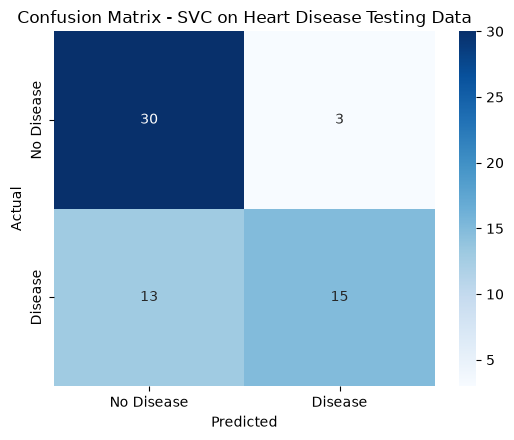

In [15]:
"""
Purpose of this section:
-------------------------
Accuracy alone can hide mistakes, so the standard classification metrics are added:
- Precision: of the patients predicted as "Disease", how many really have it?
- Recall   : of the patients who really have the disease, how many did the model find?
- F1-score : the balance (harmonic mean) of precision and recall.
- Confusion matrix: correct and wrong predictions for each class.
For a medical problem, recall for the "Disease" class is especially important,
because a missed patient (false negative) is the more costly mistake.
"""
y_true = model_predictions_df["HeartDisease"]
y_pred = model_predictions_df["Predictions"]

print("\nClassification Report:")
print("======================\n")
print(classification_report(y_true, y_pred, target_names=["No Disease (0)", "Disease (1)"]))

conf_matrix = confusion_matrix(y_true, y_pred)
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("=================\n")
print(conf_matrix_df)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

#### Step 7.6: Why These 4 Attributes? (Cross-Validation on Training Data Only)
This section supports the choice made in Step 4. Every group of 4 attributes (from the 11 attributes without missing values) is trained and scored with 5-fold cross-validation **on the training data only**. The testing data is not touched. The scores of the top groups are close to each other (differences of about 0.01 are within normal variation), so the choice also prefers attributes with a clear range of values.

In [16]:
"""
Purpose of this section:
-------------------------
Compares all 330 possible groups of 4 attributes (out of the 11 attributes with no
missing values) using 5-fold cross-validation on the TRAINING rows only.
"""
candidate_attributes = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                        "thalach", "exang", "oldpeak", "slope"]

# Training rows from the full 13-attribute data (same rows as in training-data.csv)
train_full = sample_data.loc[training_data.index]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results = []
for group in itertools.combinations(candidate_attributes, 4):
    candidate_model = make_pipeline(StandardScaler(), svm.SVC(gamma="auto", random_state=0))
    score = cross_val_score(candidate_model, train_full[list(group)], train_full["HeartDisease"], cv=cv).mean()
    results.append((group, score))

results.sort(key=lambda r: -r[1])

print("Top 5 groups of 4 attributes (5-fold cross-validation accuracy, training data only):")
print("===================================================================================\n")
top_table = PrettyTable(["Rank", "Group of 4 attributes", "CV accuracy"])
for rank, (group, score) in enumerate(results[:5], start=1):
    top_table.add_row([rank, ", ".join(group), round(score, 3)])
print(top_table)

chosen = tuple(sorted(input_attributes))
chosen_rank = [i for i, (g, s) in enumerate(results, start=1) if tuple(sorted(g)) == chosen][0]
print(f"\nSelected group ({', '.join(input_attributes)}) ranks #{chosen_rank} out of {len(results)} groups.")

Top 5 groups of 4 attributes (5-fold cross-validation accuracy, training data only):

+------+--------------------------------+-------------+
| Rank |     Group of 4 attributes      | CV accuracy |
+------+--------------------------------+-------------+
|  1   |  age, thalach, exang, oldpeak  |    0.781    |
|  2   |    sex, cp, thalach, exang     |    0.769    |
|  3   |   cp, exang, oldpeak, slope    |    0.768    |
|  4   | sex, restecg, thalach, oldpeak |    0.768    |
|  5   |  sex, thalach, exang, oldpeak  |    0.768    |
+------+--------------------------------+-------------+

Selected group (age, thalach, exang, oldpeak) ranks #1 out of 330 groups.


### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [17]:
"""
Purpose of this section:
-------------------------
Takes the four input values of a new patient. In this notebook copy, a demo patient
is pre-filled so the notebook can run from top to bottom without typing.

To type your own values interactively, replace the four lines below with:
    age_input     = float(input("Enter age (29 to 77): "))
    thalach_input = float(input("Enter maximum heart rate (71 to 202): "))
    exang_input   = float(input("Enter exercise-induced angina (0 = No, 1 = Yes): "))
    oldpeak_input = float(input("Enter ST depression (0.0 to 6.2): "))
"""
age_input = 58.0
thalach_input = 120.0
exang_input = 1.0
oldpeak_input = 2.0

print(f"age: {age_input}, thalach: {thalach_input}, exang: {exang_input}, oldpeak: {oldpeak_input}")

age: 58.0, thalach: 120.0, exang: 1.0, oldpeak: 2.0


#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [18]:
"""
Purpose of this section:
-------------------------
Checks that every value lies inside the range seen in the training data, then
converts the input into a feature vector (DataFrame) with the same four columns
and the same order as the sample data.
"""
user_values = {"age": age_input, "thalach": thalach_input, "exang": exang_input, "oldpeak": oldpeak_input}

for attribute, value in user_values.items():
    low, high = input_ranges[attribute]
    if not (low <= value <= high):
        raise ValueError(f"{attribute} = {value} is outside the valid range {low} to {high}")
if user_values["exang"] not in (0.0, 1.0):
    raise ValueError("exang must be 0 (No) or 1 (Yes)")

user_input = pd.DataFrame({k: [v] for k, v in user_values.items()})[input_attributes]

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

    age  thalach  exang  oldpeak
0  58.0    120.0    1.0      2.0


#### Step 8.3: Label Encoding of Feature Vector (not required)

All inputs are already numeric, so **no label encoding is needed**. The scaling of the values happens automatically inside the saved model (Step 6.3).

#### Step 8.4: Load the Saved Model

In [19]:
"""
Purpose of this section:
-------------------------
Loads the saved model from the .pkl file for the Application Phase.
"""
model = pickle.load(open("heart_disease_model.pkl", "rb"))
print("Model loaded from heart_disease_model.pkl")

Model loaded from heart_disease_model.pkl


#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model on the Feature Vector of the Unseen Patient and Return Prediction to the User

In [20]:
"""
Purpose of this section:
-------------------------
Uses the saved model to predict whether the new patient has heart disease.
"""
predicted_disease = model.predict(user_input)[0]

if predicted_disease == 1:
    prediction = "HEART DISEASE PRESENT"
else:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|     HEART DISEASE PRESENT      |
+--------------------------------+


In [21]:
"""
Purpose of this section:
-------------------------
A few more example patients, to see how the saved model reacts to different inputs.
"""
examples = pd.DataFrame({
    "age":     [35.0, 45.0, 62.0, 70.0],
    "thalach": [185.0, 160.0, 130.0, 105.0],
    "exang":   [0.0, 0.0, 1.0, 1.0],
    "oldpeak": [0.0, 0.8, 1.8, 3.2],
})
examples["Prediction"] = np.where(model.predict(examples[input_attributes]) == 1, "Heart disease present", "No heart disease")
print(examples.to_string(index=False))

 age  thalach  exang  oldpeak            Prediction
35.0    185.0    0.0      0.0      No heart disease
45.0    160.0    0.0      0.8      No heart disease
62.0    130.0    1.0      1.8 Heart disease present
70.0    105.0    1.0      3.2 Heart disease present


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

After deployment, feedback would be collected from users and from a domain expert (for example a doctor) who compare the predictions with real diagnoses. As this model has not been used by real users yet, no real feedback exists. The cell below instead reports what the testing results already tell us about how the model fails.

In [22]:
"""
Purpose of this section:
-------------------------
Reads the confusion matrix of Step 7.5 and reports the two kinds of mistakes.
"""
true_negative, false_positive, false_negative, true_positive = confusion_matrix(y_true, y_pred).ravel()

print("Findings from the testing data:")
print("===============================\n")
print(f"- Patients with heart disease correctly found : {true_positive} of {true_positive + false_negative}  (missed: {false_negative})")
print(f"- Healthy patients correctly cleared          : {true_negative} of {true_negative + false_positive}  (wrongly flagged: {false_positive})")
print("\nA missed patient (false negative) is the more serious mistake in a medical setting,")
print("so a domain expert would likely ask for a model that misses fewer patients, even at the")
print("cost of some extra false alarms.")

Findings from the testing data:

- Patients with heart disease correctly found : 15 of 28  (missed: 13)
- Healthy patients correctly cleared          : 30 of 33  (wrongly flagged: 3)

A missed patient (false negative) is the more serious mistake in a medical setting,
so a domain expert would likely ask for a model that misses fewer patients, even at the
cost of some extra false alarms.


#### Step 9.2: Make a List of Potential Improvements

In [23]:
"""
Purpose of this section:
-------------------------
Potential improvements identified from the results above.
"""
improvements = [
    "Use more input attributes (for example chest pain type, number of vessels, thalassemia) to give the model more information than only 4 attributes",
    "Aim for higher recall on the 'Disease' class so fewer sick patients are missed",
    "Train on more patients (this data has only 303) and from more hospitals so the model generalises better",
    "Compare other models (for example Logistic Regression, Random Forest) with cross-validation",
    "Tune the SVC settings (C, gamma, class weight): this is tested in Step 9.3",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more input attributes (for example chest pain type, number of vessels, thalassemia) to give the model more information than only 4 attributes
2. Aim for higher recall on the 'Disease' class so fewer sick patients are missed
3. Train on more patients (this data has only 303) and from more hospitals so the model generalises better
4. Compare other models (for example Logistic Regression, Random Forest) with cross-validation
5. Tune the SVC settings (C, gamma, class weight): this is tested in Step 9.3


#### Step 9.3: Improve the Model Based on Feedback

The improvement that can be tried with the data we already have is tuning the SVC settings (`C`, `gamma`, and `class_weight`). The cell below tests 60 combinations with repeated 5-fold cross-validation on the **training data only**. A new setting would replace the saved model only if it beats the current one by **more than 0.01** in cross-validation accuracy; smaller differences are within normal variation.

In [24]:
"""
Purpose of this section:
-------------------------
Tries to improve the model by tuning the SVC settings. The testing data is not used.
Note: gamma="auto" means gamma = 1 / (number of inputs) = 1 / 4 = 0.25, and the
default C is 1, so the current model is the combination C=1, gamma=0.25, class_weight=None.
"""
tuning_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
tuning_pipeline = make_pipeline(StandardScaler(), svm.SVC(random_state=0))
tuning_grid = {
    "svc__C": [0.1, 0.5, 1, 2, 5, 10],
    "svc__gamma": [0.05, 0.1, 0.25, 0.5, 1.0],
    "svc__class_weight": [None, "balanced"],
}

search = GridSearchCV(tuning_pipeline, tuning_grid, cv=tuning_cv, scoring="accuracy")
search.fit(input_vector_train, np.ravel(output_label_train))

tuning_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")

current = tuning_results[(tuning_results["param_svc__C"] == 1) &
                         (tuning_results["param_svc__gamma"] == 0.25) &
                         (tuning_results["param_svc__class_weight"].isna())].iloc[0]
default_score = current["mean_test_score"]
best = tuning_results.iloc[0]

top_tuning = PrettyTable(["Rank", "C", "gamma", "class_weight", "CV accuracy"])
for _, row in tuning_results.head(5).iterrows():
    top_tuning.add_row([int(row["rank_test_score"]), row["param_svc__C"], row["param_svc__gamma"],
                        row["param_svc__class_weight"], round(row["mean_test_score"], 3)])
print("Top 5 settings (cross-validation on training data only):")
print("========================================================\n")
print(top_tuning)

print(f"\nCurrent model (C=1, gamma=0.25, class_weight=None): {default_score:.3f}  (rank {int(current['rank_test_score'])})")
print(f"Best tuned setting                                : {best['mean_test_score']:.3f}")
gain = best["mean_test_score"] - default_score
if gain > 0.01:
    print(f"\nGain of {gain:.3f} is above 0.01 -> the tuned setting would replace the model.")
else:
    print(f"\nGain of {gain:.3f} is not above 0.01 -> no meaningful improvement, so heart_disease_model.pkl is kept as it is.")

Top 5 settings (cross-validation on training data only):

+------+------+-------+--------------+-------------+
| Rank |  C   | gamma | class_weight | CV accuracy |
+------+------+-------+--------------+-------------+
|  1   | 1.0  |  0.5  |     None     |    0.781    |
|  2   | 2.0  |  0.25 |   balanced   |     0.78    |
|  3   | 2.0  |  0.1  |   balanced   |    0.778    |
|  4   | 10.0 |  0.1  |   balanced   |    0.778    |
|  5   | 1.0  |  0.25 |     None     |    0.778    |
+------+------+-------+--------------+-------------+

Current model (C=1, gamma=0.25, class_weight=None): 0.778  (rank 5)
Best tuned setting                                : 0.781

Gain of 0.003 is not above 0.01 -> no meaningful improvement, so heart_disease_model.pkl is kept as it is.


## Conclusion

In [25]:
"""
Conclusion (the numbers below are calculated from the results above).
"""
precision_d = true_positive / (true_positive + false_positive)
recall_d = true_positive / (true_positive + false_negative)

print(f"""This notebook built a Heart Disease Prediction System from the Cleveland data using four inputs
(age, thalach, exang, oldpeak) and one binary output (HeartDisease). No label encoding was needed because
all attributes are numeric; the inputs are scaled inside the model instead. A Support Vector Classifier
trained on {len(training_data)} patients reached an accuracy of {model_accuracy_score:.2f} on {len(testing_data)} unseen patients.
For the Disease class, precision is {precision_d:.2f} and recall is {recall_d:.2f}: the model found {true_positive} of the
{true_positive + false_negative} sick patients in the testing data and missed {false_negative}.
The cross-validation accuracy on the training data is {default_score:.2f}. The testing result is based on only
{len(testing_data)} patients, so it can differ from this by a few percentage points. Tuning the SVC settings gave no
meaningful gain (Step 9.3), so the main limit is the information in four attributes and the small data set.
The model is saved in heart_disease_model.pkl and can predict for a new patient without retraining.
This is an educational model on a small data set and is not a medical diagnosis tool.""")

This notebook built a Heart Disease Prediction System from the Cleveland data using four inputs
(age, thalach, exang, oldpeak) and one binary output (HeartDisease). No label encoding was needed because
all attributes are numeric; the inputs are scaled inside the model instead. A Support Vector Classifier
trained on 242 patients reached an accuracy of 0.74 on 61 unseen patients.
For the Disease class, precision is 0.83 and recall is 0.54: the model found 15 of the
28 sick patients in the testing data and missed 13.
The cross-validation accuracy on the training data is 0.78. The testing result is based on only
61 patients, so it can differ from this by a few percentage points. Tuning the SVC settings gave no
meaningful gain (Step 9.3), so the main limit is the information in four attributes and the small data set.
The model is saved in heart_disease_model.pkl and can predict for a new patient without retraining.
This is an educational model on a small data set and is not a medical diagno